# 快速介紹一下機器學習流程

機器學習 (Machine Learning) 並不是把資料丟進模型，就能直接得到準確的預測結果。我們需要經過資料讀取、探索、清理、模型訓練與評估等步驟，才能建立一個可靠的機器學習模型。

為了更容易理解，這裡使用一個生活化的例子：假設我們想建立一個「房價預測系統」，讓電腦根據房屋的條件，自動預測房屋價格。

![](./assets/已嚴肅觀看.png)

## 1. 讀取資料集

機器學習需要資料才能學習，就像學生需要課本和練習題，才能逐漸掌握解題方法。

假設我們手上有一份 `house.csv`，記錄過去成交的房屋資料：

| 坪數 | 屋齡 | 房間數 | 房價 (萬元) |
| ---- | ---- | ------ | ----------- |
| 20   | 15   | 2      | 500         |
| 30   | 10   | 3      | 800         |
| 40   | 5    | 3      | 1200        |
| 50   | 2    | 4      | 1600        |
| 25   | 20   | 2      | 550         |

我們可以使用 Pandas 將資料讀取進來。

In [2]:
import pandas as pd


### 讀取資料集
df = pd.read_csv("./data/house.csv")

### 查看前 5 筆資料
display(df.head())

,坪數,屋齡,房間數,房價
0,20.0,15,2,500
1,30.0,10,3,800
2,40.0,5,3,1200
3,50.0,2,4,1600
4,25.0,20,2,550


## 2. 探索資料 (EDA)

EDA (Exploratory Data Analysis) 中文稱為探索性資料分析。

先不要急著把資料丟進模型，應該先了解資料長什麼樣子。例如：

- 這份資料有多少筆房屋成交紀錄？
- 有哪些欄位？坪數、屋齡還是房價？
- 有沒有欄位出現空白？
- 房價最高是多少？最低是多少？
- 坪數越大的房屋，價格是否通常越高？

![](./assets/為什麼你會流淚.gif)

In [4]:
### 查看前 5 筆資料
display(df.head())

### 查看資料筆數與欄位數量
print(df.shape)

### 查看欄位資料型態
display(df.info())

### 查看統計資訊
display(df.describe())

### 查看缺失值數量
display(df.isnull().sum())

,坪數,屋齡,房間數,房價
0,20.0,15,2,500
1,30.0,10,3,800
2,40.0,5,3,1200
3,50.0,2,4,1600
4,25.0,20,2,550


(300, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   坪數      300 non-null    float64
 1   屋齡      300 non-null    int64  
 2   房間數     300 non-null    int64  
 3   房價      300 non-null    int64  
dtypes: float64(1), int64(3)
memory usage: 9.5 KB


None

,坪數,屋齡,房間數,房價
count,300.000000,300.000000,300.000000,300.000000
mean,43.256000,20.233333,3.126667,1174.713333
std,17.929039,11.683345,1.304977,572.178058
min,12.200000,0.000000,1.000000,180.000000
25%,28.125000,10.000000,2.000000,654.000000
50%,42.050000,19.500000,3.000000,1181.000000
75%,58.075000,31.000000,4.000000,1629.000000
max,74.800000,40.000000,5.000000,2437.000000


坪數     0
屋齡     0
房間數    0
房價     0
dtype: int64

## 3. 資料清理 (Data Cleaning)

真實世界的資料不一定乾淨，可能出現缺失值、重複資料或錯誤數值。

例如：

| 坪數 | 屋齡 | 房間數 | 房價 (萬元) | 問題       |
| ---- | ---- | ------ | ----------- | ---------- |
| 20   | 15   | 2      | 500         | 正常       |
| 30   | 10   | 3      | 800         | 正常       |
| 空白 | 5    | 3      | 1200        | 缺失值     |
| -50  | 2    | 4      | 1600        | 坪數不合理 |
| 20   | 15   | 2      | 500         | 可能重複   |

如果直接使用這些資料訓練模型，可能影響模型的學習效果。

常見的清理方式包括：

- 缺失值：刪除資料，或使用平均數、中位數填補。
- 重複資料：確認是否為重複紀錄，再決定是否刪除。
- 錯誤數值：例如坪數為負數，應確認資料來源並修正或排除。
- 資料格式：例如將 `"800萬"` 轉換為數值 `800`。

In [8]:
### 刪除完全相同的重複資料
df = df.drop_duplicates()

### 排除坪數不合理的資料
df = df[df["坪數"].isna() | (df["坪數"] > 0)]

### 刪除房價缺失的資料
df = df.dropna(subset=["房價"])

### 顯示清理後的資料筆數
print("清理後資料筆數：", len(df))

清理後資料筆數： 300


## 4. 選擇 Features 與 Target

接下來要決定：

我們希望模型根據哪些資訊，預測什麼結果？

機器學習中有兩個重要概念：

| 名稱            | 符號 | 說明                 | 房價預測例子       |
| --------------- | ---- | -------------------- | ------------------ |
| Features (特徵) | X    | 提供給模型參考的資訊 | 坪數、屋齡、房間數 |
| Target (目標)   | y    | 希望模型預測的答案   | 房價               |

![](./assets/選擇Features與Target.png)

In [11]:
### 選擇 Features
X = df[["坪數", "屋齡", "房間數"]]

### 選擇 Target
y = df["房價"]

print(X.shape)
print(y.shape)

(300, 3)
(300,)


## 5. 切分 Train / Test

如果模型只在學習過的資料上進行測試，很難知道它是否真的具備預測新資料的能力。

因此，我們需要將資料分成：

| 資料集         | 用途         | 白話理解   |
| -------------- | ------------ | ---------- |
| Train (訓練集) | 提供模型學習 | 平常練習題 |
| Test (測試集)  | 評估模型表現 | 正式考試   |

假設我們有 1000 筆房屋資料，採用 80% / 20% 的比例：

![](./assets/切分Train&Test.png)

In [ ]:
from sklearn.model_selection import train_test_split


### 切分 Train 80%、Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為測試集
    random_state=42 # 固定隨機種子，讓結果可以重現
)



## 6. 建立資料前處理 Pipeline

不同 Features 的數值範圍可能差很多。

例如：

| Feature | 數值範圍 |
| ------- | -------- |
| 坪數    | 10～100  |
| 屋齡    | 0～50    |
| 房間數  | 1～6     |

對某些演算法，例如 KNN、SVM，數值尺度的差異可能影響模型學習。

![](./assets/這個東西很明顯道德上面有問題.png)

因此我們可以使用 `StandardScaler` 將 Features 標準化。

同時也可以使用 `SimpleImputer` 處理缺失值。


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


### 建立資料前處理 Pipeline
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 使用中位數填補缺失值
    ("scaler", StandardScaler()) # 將 Features 標準化
])

## 7. 建立模型

資料準備完成後，就可以選擇機器學習演算法。

不同問題適合不同模型。

| 問題               | 類型           | 常見演算法                       |
| ------------------ | -------------- | -------------------------------- |
| 預測房屋價格       | Regression     | Linear Regression、Random Forest |
| 預測學生是否及格   | Classification | Logistic Regression、KNN         |
| 將顧客分成不同群體 | Clustering     | K-Means、DBSCAN                  |

假設我們要預測房價，可以選擇 Linear Regression。

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立完整模型
model = Pipeline([
    ("preprocessor", preprocessor), # 資料前處理
    ("regression", LinearRegression()) # 線性迴歸模型
])

## 8. 訓練模型

建立模型之後，需要使用訓練資料讓模型學習。

模型會嘗試找出 Features 與 Target 之間的關係。

例如，它可能學到：

- 坪數越大，房價通常越高。
- 在其他條件相近時，屋齡越高，房價可能越低。
- 房間數量可能與房價存在某種關係。

這些只是可能學到的規律，實際結果取決於訓練資料。

![](./assets/perfect.png)

In [19]:
### 訓練模型
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                                 ('scaler', StandardScaler())])),
                ('regression', LinearRegression())])

## 9. 使用模型預測

模型訓練完成後，就可以使用 `model.predict()` 進行預測。

> 白話理解： 就像學生已經完成練習，現在老師拿出新的題目，讓學生自己作答。
>
> 模型也一樣，訓練完成後，就能根據新的房屋條件預測價格。

但預測結果不一定完全正確，因此還需要評估。

In [25]:
### 使用測試資料進行預測
y_pred = model.predict(X_test)

### 初階寫法
print(y_pred[:5])
print(y_test[:5])

### 進階寫法：建立預測結果 DataFrame
df_result = pd.DataFrame({
    "真實房價": y_test.iloc[:10].to_numpy(),
    "預測房價": y_pred[:10]
})

### 顯示前 10 筆預測結果
display(df_result)

[ 402.2804607  1424.78440946 1216.02619603 1115.40168712 2147.52697851]
203     498
266    1246
152    1193
9      1296
233    2223
Name: 房價, dtype: int64


,真實房價,預測房價
0,498,402.280461
1,1246,1424.784409
2,1193,1216.026196
3,1296,1115.401687
4,2223,2147.526979
5,1985,1998.512435
6,1461,1521.570010
7,711,856.062514
8,1630,1642.376597
9,1713,1830.582542


## 10. 評估模型表現

模型能夠預測，不代表預測一定準確。

如果學生每一題都答得很接近正確答案，代表學習成果不錯。但如果每題都差很多，就需要回頭檢查學習方法，或重新練習。

機器學習也是如此。如果模型表現不好，可以嘗試調整 Features、模型參數，或改善資料品質。

我們需要比較模型的預測結果與真實答案，判斷模型表現。例如：

- 真實房價：800 萬
- 預測房價：780 萬
- 預測誤差：20 萬

回歸問題常用以下指標：

| 指標 | 說明                     | 判斷方向          |
| ---- | ------------------------ | ----------------- |
| MAE  | 平均絕對誤差             | 越小越好          |
| MSE  | 平均平方誤差             | 越小越好          |
| RMSE | 均方根誤差               | 越小越好          |
| R²   | 模型對目標變異的解釋程度 | 通常越接近 1 越好 |

In [26]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score


### 評估模型表現
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MAE：", mae)
print("RMSE：", rmse)
print("R²：", r2)

MAE： 82.81175307598735
RMSE： 105.765302825546
R²： 0.9631931615547082


## 11. 視覺化預測結果

單純看 MAE、RMSE 等數字，有時候不容易發現模型的問題。因此我們可以透過圖表觀察預測結果。

例如：將真實房價與預測房價畫成 Scatter Plot。

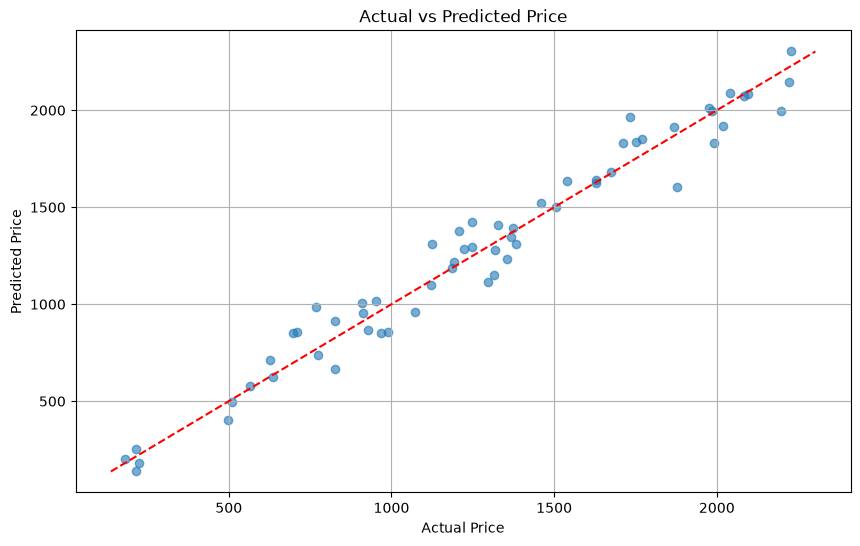

In [27]:
import matplotlib.pyplot as plt


### 視覺化預測結果
plt.figure(figsize=(10, 6))

### 繪製真實值與預測值
plt.scatter(y_test, y_pred, alpha=0.6)

### 設定完美預測參考線
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

### 設定圖表
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.grid(True)

plt.show()

不過，實際開發時不一定只執行一次。當模型表現不理想，我們往往需要回頭重新檢查資料、調整特徵或更換演算法，反覆改善模型。

## 機器學習流程整理

| 步驟                      | 要做什麼                   | 白話理解                 |
| ------------------------- | -------------------------- | ------------------------ |
| 1. 讀取資料集             | 將資料載入 Python          | 打開課本                 |
| 2. 探索資料               | 了解資料內容與分布         | 翻閱課本，了解有哪些內容 |
| 3. 資料清理               | 處理缺失值、重複與錯誤資料 | 修正教材中的錯誤         |
| 4. 選擇 Features / Target | 決定輸入資訊與預測目標     | 確認題目與答案           |
| 5. 切分 Train / Test      | 分開訓練與測試資料         | 練習題與正式考試分開     |
| 6. 建立 Pipeline          | 統一資料前處理流程         | 整理學習資料的格式       |
| 7. 建立模型               | 選擇適合的演算法           | 選擇解題方法             |
| 8. 訓練模型               | 讓模型學習資料規律         | 學生開始練習             |
| 9. 使用模型預測           | 預測未參與訓練的資料       | 學生開始作答             |
| 10. 評估模型              | 計算模型的預測誤差         | 老師批改考卷             |
| 11. 視覺化結果            | 透過圖表分析模型表現       | 分析哪些題目容易答錯     |

這 11 個步驟可以當作監督式機器學習的基本工作流程，尤其適合 Regression 與 Classification。